# TP2 KASDAD - Regresi `threat_rank`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

LightGBM L1 memakai fitur structured dan TF-IDF/SVD32, dengan rank blend yang dipilih melalui inner validation. Metrik utama: **MAE**.

Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan dan data

Sediakan official `classification/Train.csv` untuk availability EDA dan `regression/Train.csv` untuk model. Letakkan keduanya di bawah `TP2_DATA_DIR` (default: `data/raw/` di current directory atau parent); `TP2_DATA_DIR` menunjuk folder yang berisi `classification/` dan `regression/`. Seluruh helper EDA, preprocessing, feature engineering, model, dan evaluasi custom berada di cell notebook ini; tidak ada impor dari file project lokal. Test inference tetap nonaktif.

Dependensi Python: NumPy, pandas, SciPy, scikit-learn, LightGBM, Matplotlib, threadpoolctl, IPython/Jupyter.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from threadpoolctl import threadpool_limits


def find_data_root():
    configured = os.environ.get("TP2_DATA_DIR")
    if configured:
        root = Path(configured).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"TP2_DATA_DIR is not a directory: {root}")
        return root
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate / "data" / "raw", candidate / "raw", candidate):
            if any((root / task).is_dir() for task in ("classification", "regression")):
                return root
    return current / "data" / "raw"


DATA_ROOT = find_data_root()


def task_files(task, root=None):
    if task not in {"classification", "regression"}:
        raise ValueError(f"Unknown task: {task}")
    folder = (Path(root) if root is not None else DATA_ROOT) / task
    files = {}
    for role, stem in (
        ("train", "train"),
        ("test", "test"),
        ("sample", "samplesubmission"),
    ):
        matches = [
            path
            for path in folder.iterdir()
            if path.is_file()
            and path.suffix.lower() == ".csv"
            and path.stem.lower() == stem
        ] if folder.is_dir() else []
        if len(matches) > 1:
            raise ValueError(f"Ambiguous {task}/{role}: {[path.name for path in matches]}")
        files[role] = matches[0] if matches else None
    return files


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def stream_missing_mask(frame):
    series = frame["signal_stream"] if isinstance(frame, pd.DataFrame) else frame
    return (
        series.isna()
        | series.fillna("").astype(str).str.strip().eq("")
    ).to_numpy(dtype=bool)


def array_digest(values):
    array = np.asarray(values, dtype="<f8")
    return hashlib.sha256(array.tobytes(order="C")).hexdigest()


plt.rcParams.update(
    {
        "figure.figsize": (9, 4.5),
        "figure.dpi": 120,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
get_ipython().run_line_magic("matplotlib", "inline")
print("Data root:", DATA_ROOT)
print("Set TP2_DATA_DIR to the parent of classification/ and regression/ if needed.")


Data root: C:\Users\Sam\AppData\Local\Temp\samuel_root_standalone_usbieehu\data\raw
Set TP2_DATA_DIR to the parent of classification/ and regression/ if needed.


## 2. Dataset dan target

Model memprediksi `threat_rank` pada skala 0-100. Ringkasan berikut memakai official Regression Train; bagian EDA kemudian memakai Classification Train secara terpisah.

In [2]:
EXPECTED_CLASSIFICATION_TRAIN_SHA256 = (
    "875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c"
)
EXPECTED_REGRESSION_TRAIN_SHA256 = (
    "756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082"
)
CLASSIFICATION_FILES = task_files("classification")
REGRESSION_FILES = task_files("regression")
if CLASSIFICATION_FILES["train"] is None or REGRESSION_FILES["train"] is None:
    raise FileNotFoundError(
        "Diperlukan classification/Train.csv untuk EDA dan regression/Train.csv untuk model."
    )

classification_train = pd.read_csv(CLASSIFICATION_FILES["train"])
train = pd.read_csv(REGRESSION_FILES["train"])
assert sha256_file(CLASSIFICATION_FILES["train"]) == EXPECTED_CLASSIFICATION_TRAIN_SHA256
regression_train_sha256 = sha256_file(REGRESSION_FILES["train"])
assert regression_train_sha256 == EXPECTED_REGRESSION_TRAIN_SHA256
assert classification_train["record_id"].notna().all()
assert classification_train["record_id"].is_unique
assert train["record_id"].notna().all() and train["record_id"].is_unique
assert train["threat_rank"].notna().all()
assert train["threat_rank"].between(0, 100).all()
assert train["cycle_code"].between(47, 79).all()

overview = pd.DataFrame(
    [
        {
            "Dataset": "Regression Train",
            "Rows": len(train),
            "Columns": train.shape[1],
            "Missing target": int(train["threat_rank"].isna().sum()),
            "Unique target values": int(train["threat_rank"].nunique()),
            "Cycles": f"{train.cycle_code.min()}-{train.cycle_code.max()}",
        },
        {
            "Dataset": "Classification Train for EDA",
            "Rows": len(classification_train),
            "Columns": classification_train.shape[1],
            "Missing target": int(classification_train["artifact_signal"].isna().sum()),
            "Unique target values": int(classification_train["artifact_signal"].nunique()),
            "Cycles": f"{classification_train.cycle_code.min()}-{classification_train.cycle_code.max()}",
        },
    ]
)
display(overview)
print("SHA-256 Classification Train:", EXPECTED_CLASSIFICATION_TRAIN_SHA256)
print("SHA-256 Regression Train:", regression_train_sha256)


,Dataset,Rows,Columns,Missing target,Unique target values,Cycles
0,Regression Train,50608,19,0,34333,47-79
1,Classification Train for EDA,50608,19,0,2,47-79


SHA-256 Classification Train: 875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c
SHA-256 Regression Train: 756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082


`impact_load` dan `entry_friction` menjadi fitur resmi TP2; label/model TP1 tidak digabungkan. ID dan target lain dikecualikan. Format campuran dan nilai kosong ditangani di pipeline.

## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train. Analisis ini sama pada kedua notebook; tidak memasukkan label Classification ke model Regression.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [3]:
# Inline availability EDA definitions; source SHA-256 2240da85704003ebeeb36b147ac01181f8f45da4e030af31c6cc7368dc2273d1.
"""Descriptive analysis helpers for Classification stream availability.

All contrasts are descriptive. Quantile boundaries are computed from
``text_load`` only; neither availability nor the outcome determines bins.
"""

from itertools import product
from typing import Iterable

import numpy as np
import pandas as pd

AVAILABILITY_ORDER = ("present", "missing")
PERIODS = ((47, 57, "47–57"), (58, 68, "58–68"), (69, 79, "69–79"))


def wilson_interval(successes: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    """Return a Wilson 95% interval for one binomial proportion."""
    if n <= 0 or successes < 0 or successes > n:
        raise ValueError("Wilson interval requires 0 <= successes <= n and n > 0")
    p = successes / n
    denominator = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return float(max(0.0, center - half_width)), float(min(1.0, center + half_width))


def prepare_availability_frame(
    train: pd.DataFrame,
    stream_missing: Iterable[bool],
) -> pd.DataFrame:
    """Validate official raw columns and create a small analysis-only frame."""
    required = {"record_id", "cycle_code", "signal_stream", "text_load", "artifact_signal"}
    missing_columns = sorted(required - set(train.columns))
    if missing_columns:
        raise ValueError(f"Official Classification Train lacks columns: {missing_columns}")
    mask = np.asarray(list(stream_missing), dtype=bool)
    if len(mask) != len(train):
        raise ValueError("stream_missing must have one value per training row")
    if train["record_id"].isna().any() or train["record_id"].duplicated().any():
        raise ValueError("record_id must be complete and unique")
    target = pd.to_numeric(train["artifact_signal"], errors="raise")
    if target.isna().any() or not target.isin([0, 1]).all():
        raise ValueError("artifact_signal must be complete binary 0/1")
    cycle = pd.to_numeric(train["cycle_code"], errors="raise")
    if cycle.isna().any() or not np.equal(cycle, np.floor(cycle)).all():
        raise ValueError("cycle_code must be complete integer values")
    text_load = pd.to_numeric(train["text_load"], errors="raise")
    if text_load.isna().any() or not np.isfinite(text_load).all():
        raise ValueError("text_load must be complete and finite")

    period_labels = np.select(
        [cycle.between(start, end) for start, end, _ in PERIODS],
        [label for _, _, label in PERIODS],
        default="outside expected cycles",
    )
    if np.any(period_labels == "outside expected cycles"):
        raise ValueError("Train contains cycle_code outside the documented periods 47–79")
    return pd.DataFrame(
        {
            "record_id": train["record_id"].to_numpy(),
            "cycle_code": cycle.astype(int).to_numpy(),
            "period": period_labels,
            "text_load": text_load.astype(float).to_numpy(),
            "artifact_signal": target.astype(int).to_numpy(),
            "availability": np.where(mask, "missing", "present"),
        },
        index=train.index,
    )


def prevalence_table(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    """Return denominators, positive counts, and proportions by requested groups."""
    if not group_columns:
        raise ValueError("At least one grouping column is required")
    grouped = (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(n=("artifact_signal", "size"), positive=("artifact_signal", "sum"))
        .reset_index()
    )
    grouped["prevalence"] = grouped["positive"] / grouped["n"]
    return grouped


def add_global_quantile_bins(frame: pd.DataFrame, q: int) -> tuple[pd.DataFrame, np.ndarray]:
    """Add global, outcome-blind quantile bins of text_load and return edges."""
    if q < 2:
        raise ValueError("q must be at least 2")
    if frame["text_load"].isna().any():
        raise ValueError("text_load cannot be missing when creating bins")
    labels, edges = pd.qcut(frame["text_load"], q=q, labels=False, retbins=True, duplicates="raise")
    result = frame.copy()
    result[f"text_load_q{q}"] = labels.astype(int)
    return result, np.asarray(edges, dtype=float)


def standardized_contrast(
    frame: pd.DataFrame,
    strata: list[str],
    *,
    min_support: int = 20,
    availability_column: str = "availability",
    outcome_column: str = "artifact_signal",
) -> tuple[dict, pd.DataFrame]:
    """Standardize both availability rates to the same pooled supported-cell mix.

    Cells qualify only if both availability groups have at least ``min_support``
    observations. A common cell weight is its combined denominator divided by
    all rows in supported cells. The returned summary keeps group-specific
    support and coverage denominators explicit.
    """
    if not strata or min_support < 1:
        raise ValueError("strata must be non-empty and min_support positive")
    needed = set(strata) | {availability_column, outcome_column}
    if needed - set(frame.columns):
        raise ValueError(f"Missing columns for standardization: {sorted(needed - set(frame.columns))}")
    if frame[list(strata) + [availability_column, outcome_column]].isna().any().any():
        raise ValueError("strata, availability, and outcome must be complete")
    if not frame[availability_column].isin(AVAILABILITY_ORDER).all():
        raise ValueError("availability values must be 'present' or 'missing'")
    if not frame[outcome_column].isin([0, 1]).all():
        raise ValueError("outcome must be binary 0/1")

    aggregation = (
        frame.groupby(strata + [availability_column], observed=True, dropna=False)[outcome_column]
        .agg(n="size", positive="sum")
        .reset_index()
    )
    domains = []
    for column in strata:
        values = list(pd.unique(frame[column]))
        try:
            values = sorted(values)
        except TypeError:
            pass
        domains.append(values)
    # Build lookup without relying on pandas' namedtuple field behavior for
    # arbitrary column names such as a caller-provided stratum label.
    indexed = {}
    for _, row in aggregation.iterrows():
        key = tuple(row[column] for column in strata)
        indexed[(key, row[availability_column])] = (int(row["n"]), int(row["positive"]))

    rows = []
    for cell_key in product(*domains):
        cell = dict(zip(strata, cell_key))
        state = {}
        for availability in AVAILABILITY_ORDER:
            n, positive = indexed.get((cell_key, availability), (0, 0))
            state[availability] = {
                "n": n,
                "positive": positive,
                "prevalence": positive / n if n else np.nan,
            }
        combined_n = state["present"]["n"] + state["missing"]["n"]
        supported = all(state[name]["n"] >= min_support for name in AVAILABILITY_ORDER)
        rows.append(
            {
                **cell,
                "n_present": state["present"]["n"],
                "positive_present": state["present"]["positive"],
                "prevalence_present": state["present"]["prevalence"],
                "n_missing": state["missing"]["n"],
                "positive_missing": state["missing"]["positive"],
                "prevalence_missing": state["missing"]["prevalence"],
                "combined_n": combined_n,
                "supported": supported,
            }
        )
    cells = pd.DataFrame(rows)
    supported = cells.loc[cells["supported"]].copy()
    if supported.empty:
        raise ValueError("No strata meet minimum support for both availability groups")
    supported_rows = int(supported["combined_n"].sum())
    weighted = {}
    for availability in AVAILABILITY_ORDER:
        weighted[availability] = float(
            np.sum(
                (supported["combined_n"] / supported_rows)
                * supported[f"prevalence_{availability}"].to_numpy(dtype=float)
            )
        )
    total_by_group = {
        name: int(frame[availability_column].eq(name).sum()) for name in AVAILABILITY_ORDER
    }
    covered_by_group = {
        "present": int(supported["n_present"].sum()),
        "missing": int(supported["n_missing"].sum()),
    }
    summary = {
        "strata": strata,
        "minimum_n_per_availability_per_cell": int(min_support),
        "cells_total": int(len(cells)),
        "cells_supported": int(supported.shape[0]),
        "supported_rows_total": supported_rows,
        "coverage_all_rows": float(supported_rows / len(frame)),
        "covered_rows_by_availability": covered_by_group,
        "total_rows_by_availability": total_by_group,
        "coverage_by_availability": {
            name: float(covered_by_group[name] / total_by_group[name])
            for name in AVAILABILITY_ORDER
        },
        "standardized_prevalence": weighted,
        "standardized_missing_minus_present_pp": float(100 * (weighted["missing"] - weighted["present"])),
        "standardization_weight": "combined cell n divided by all rows in supported cells; same weights for both groups",
        "support_rule": "each supported cell has at least min_support rows in both availability groups",
    }
    return summary, cells


In [4]:
eda_train = classification_train
eda_analysis = prepare_availability_frame(
    eda_train, stream_missing_mask(eda_train["signal_stream"])
)
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis["availability"].unique()) == {"present", "missing"}
assert eda_analysis["cycle_code"].min() == 47
assert eda_analysis["cycle_code"].max() == 79
eda_COLORS = {"present": "#1f4e79", "missing": "#d17a22"}
print(
    f"EDA source: Classification Train | {len(eda_train):,} rows x "
    f"{eda_train.shape[1]} columns | target artifact_signal | cycles 47-79"
)


EDA source: Classification Train | 50,608 rows x 19 columns | target artifact_signal | cycles 47-79


### EDA 2. Gambaran data

In [5]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')


,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

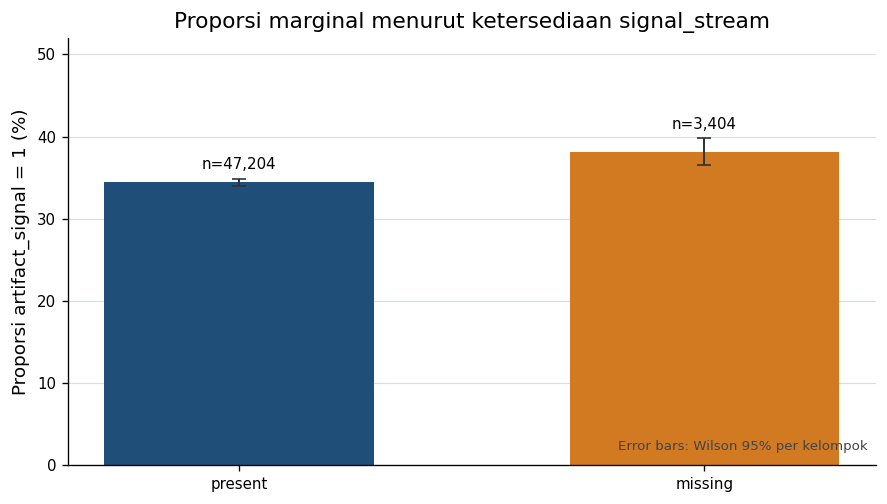

In [6]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()


Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


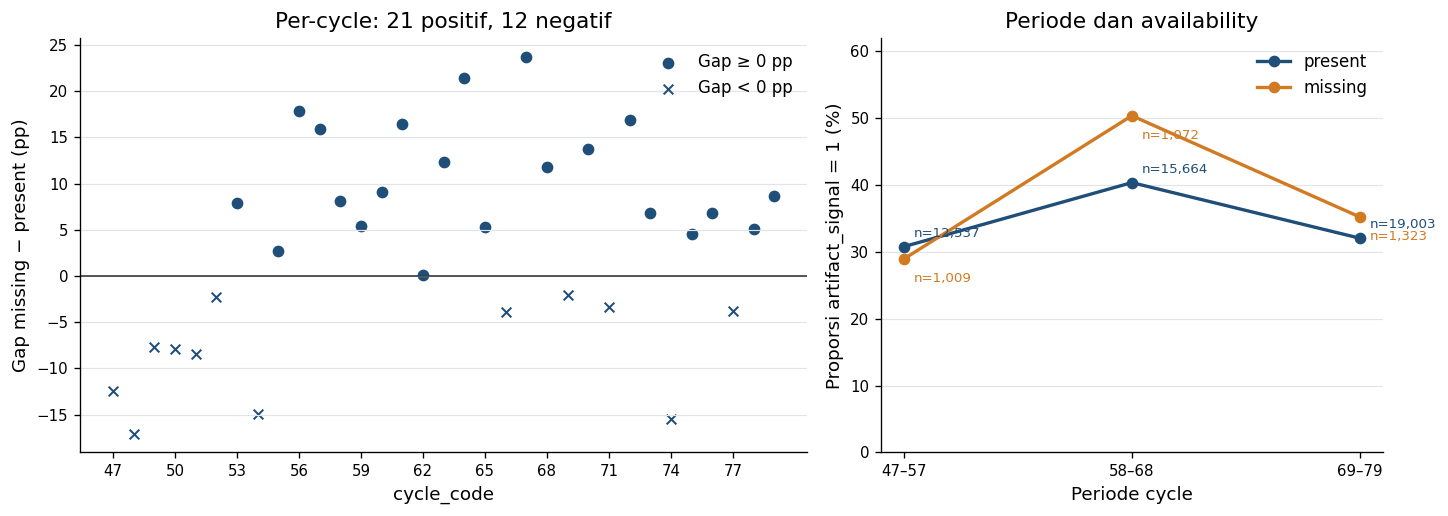

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [7]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))


Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


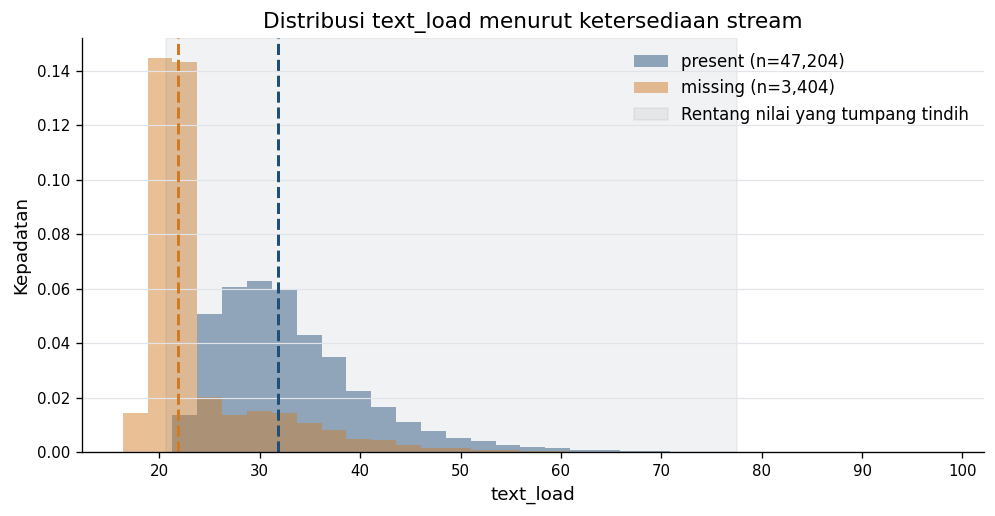

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [8]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))


Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [9]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')


,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


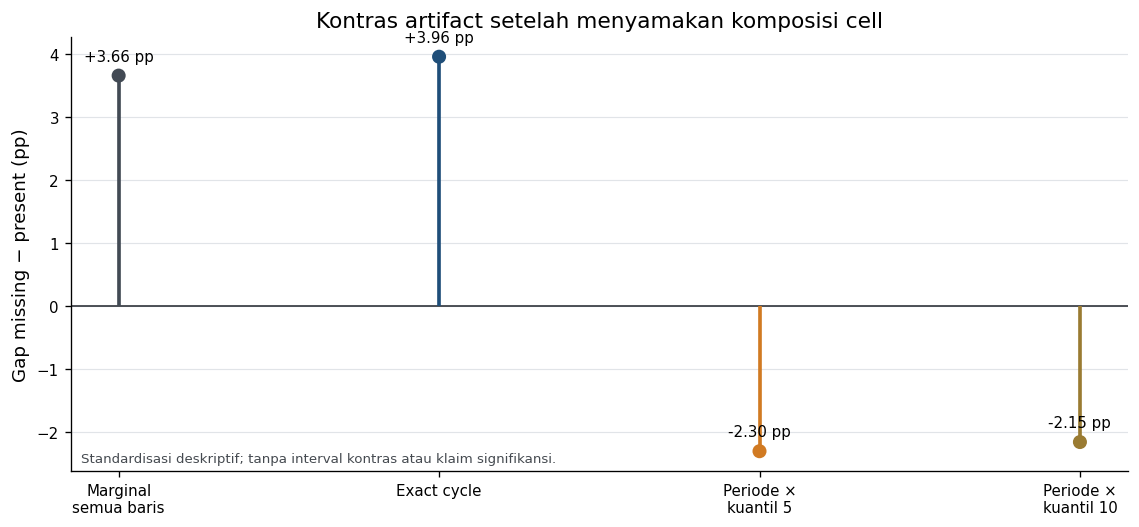

In [10]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()


Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [11]:
display(Markdown('\n\n'.join([
    f"Gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle {eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; periode dan volume {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok) dan {eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).",
    f"Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup {eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} baris ({eda_period_q10['coverage_all_rows']:.2%}); {eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.",
    "Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa."
])))


Gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode dan volume -2.30 pp (5 kelompok) dan -2.15 pp (10 kelompok).

Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup 47,740/50,608 baris (94.33%); 28/30 kelompok didukung.

Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa.

### EDA 8. Kesimpulan

Ada perbedaan proporsi label, tetapi arahnya bergantung pada cara laporan dibandingkan. Pada seluruh data, teks kosong memiliki proporsi label 1 **38,13%**, dibanding **34,47%** pada teks terisi: gap **+3,66 pp**. Setelah komposisi setiap cycle disamakan, gap tetap positif **+3,96 pp** dengan seluruh **33 cycle dan 100% baris** didukung.

Ketika periode dan kelompok volume disamakan bersama, gap berbalik menjadi **-2,30 pp** pada 5 kelompok volume (**100% coverage**) dan **-2,15 pp** pada 10 kelompok (**94,33% coverage; 28/30 strata**). Jadi, pembalikan arah muncul pada penyesuaian gabungan waktu dan volume, bukan pada waktu saja.

Status teks kosong tidak cukup untuk menyimpulkan proporsi artifact tanpa memperhatikan komposisi laporan. Penyesuaian masih memakai rentang volume yang kasar; hasil ini bersifat deskriptif, tidak membuktikan sebab-akibat, dan belum memastikan pola yang sama pada Test.

## 4. Perkembangan pendekatan

MAE mengukur rata-rata selisih absolut; median menjadi baseline yang sesuai. TP1 memiliki target diskret yang terkonsentrasi, sedangkan TP2 memiliki **34.333 nilai unik**. Karena itu, multiclass per nilai target TP1 tidak disalin.

Tabel berikut adalah hasil historis enam window temporal. Primary mengevaluasi horizon 4 cycle, sedangkan H12 horizon 12 cycle. Pooled MAE menimbang baris, equal-cycle menimbang cycle. H12 memakai ulang baris primary dan bukan replikasi independen.

### Asal hasil perbandingan

Tabel historis merangkum eksperimen sebelumnya dan disertakan langsung di notebook. Tabel ini menjadi pembanding; evaluasi temporal di bagian berikut tetap dilatih dan dihitung ulang dari data mentah.

,approach,primary MAE,H12 MAE
0,Global median,24.99995,24.99995
1,Median impact,15.56157,15.94048
2,Median impact + EF,15.31140,15.67423
3,Standardized OLS,15.62263,15.83498
4,HGB squared error,15.57102,15.89889
5,"HGB two features, MAE",15.14899,15.47789
6,"HGB expanded, MAE",13.34984,15.57724


,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
Recipe,,,,,
hybrid_ridge,12.55130,12.79007,13.93812,16.39546,11.85908
svd_hgb,12.36618,12.67774,14.71412,17.27256,12.54955
lgb_inner,13.06489,13.32251,15.60415,17.88659,13.67310
structured_ridge,14.17865,14.33300,15.20582,17.22924,13.49390
lgb_text,11.93160,12.28355,14.70404,17.47326,12.36114


,window,MAE,n
0,W1,16.40578,4114
1,W2,12.04287,6493
2,W3,12.35421,7078
3,W4,11.99939,4950
4,W5,10.77491,7462
5,W6,10.30343,8491
6,H12_E,17.47326,17685
7,H12_L,12.36114,20903


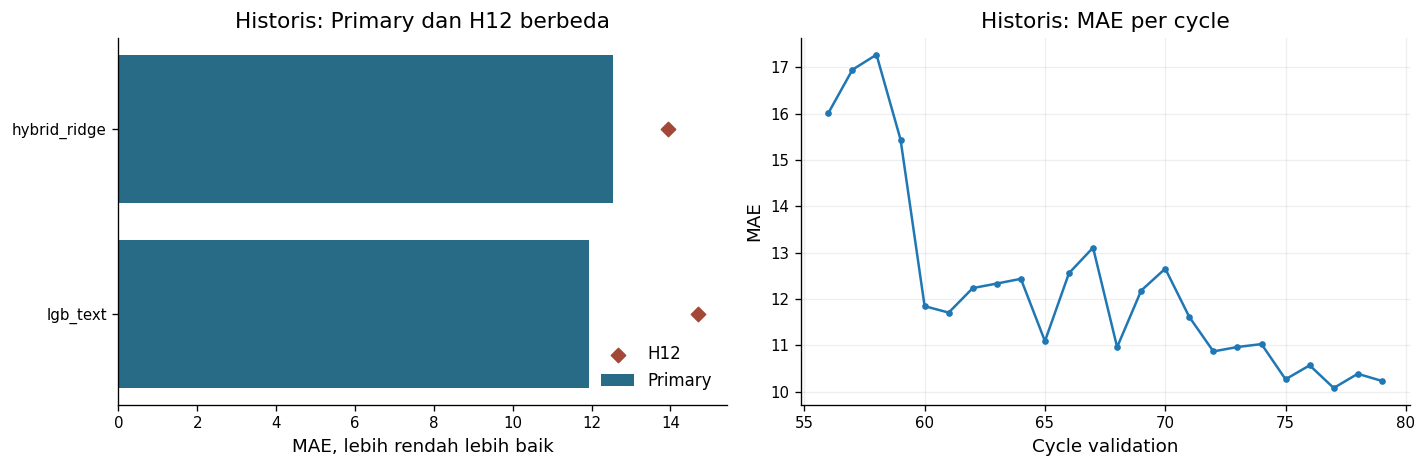

Historical source SHA-256:
  reports/round1/results.json: 2d92c744d9dc3076664f2fea312504e147baa2f931fbd22a2c17ff5fe321b376
  reports/regression_round2/results.json: 75e7d54ed58f414a271409481a59337fd030bb391e6d65941137dff67f0345ac
  reports/regression_research/report_data.json: d1681c17c1938e21668205f15a582bc90d1db419e5033de606502252b0104f95
  reports/regression_research/stage5_lgb_text.json: a7fb69f80c4aa0d91c01f50669b2e921dd51e1f04a7a91153ad6e71565837cf5


In [12]:
HISTORICAL_REGRESSION_W6_SHA256 = '5c7eadad8122fbc6c2576d369fc1d54c96a768142a267ab57341b57ee6b7072e'
HISTORICAL_PROVENANCE = {'reports/round1/results.json': '2d92c744d9dc3076664f2fea312504e147baa2f931fbd22a2c17ff5fe321b376',
 'reports/regression_round2/results.json': '75e7d54ed58f414a271409481a59337fd030bb391e6d65941137dff67f0345ac',
 'reports/regression_research/report_data.json': 'd1681c17c1938e21668205f15a582bc90d1db419e5033de606502252b0104f95',
 'reports/regression_research/stage5_lgb_text.json': 'a7fb69f80c4aa0d91c01f50669b2e921dd51e1f04a7a91153ad6e71565837cf5'}
historical_round1 = pd.DataFrame([{'approach': 'Global median',
  'primary MAE': 24.99995439255727,
  'H12 MAE': 24.999953235461803},
 {'approach': 'Median impact',
  'primary MAE': 15.561566673577277,
  'H12 MAE': 15.940477432103245},
 {'approach': 'Median impact + EF',
  'primary MAE': 15.311399701979889,
  'H12 MAE': 15.674229658183892},
 {'approach': 'Standardized OLS',
  'primary MAE': 15.622633297651307,
  'H12 MAE': 15.83497986243071},
 {'approach': 'HGB squared error',
  'primary MAE': 15.571019136538627,
  'H12 MAE': 15.898887106553621},
 {'approach': 'HGB two features, MAE',
  'primary MAE': 15.148985650926262,
  'H12 MAE': 15.477893321106137},
 {'approach': 'HGB expanded, MAE',
  'primary MAE': 13.349836350894211,
  'H12 MAE': 15.577240029210996}])
display(historical_round1.round(5))
historical_models = pd.DataFrame([{'Recipe': 'hybrid_ridge',
  'Primary MAE': 12.551304697152961,
  'Equal-cycle MAE': 12.790073160003772,
  'H12 MAE': 13.938115395708403,
  'H12_E': 16.39545540608638,
  'H12_L': 11.859080899055558},
 {'Recipe': 'svd_hgb',
  'Primary MAE': 12.36618114115671,
  'Equal-cycle MAE': 12.67774260401219,
  'H12 MAE': 14.714120448143928,
  'H12_E': 17.27256119171744,
  'H12_L': 12.54954959467325},
 {'Recipe': 'lgb_inner',
  'Primary MAE': 13.064889419500766,
  'Equal-cycle MAE': 13.322505244690326,
  'H12 MAE': 15.604152895892863,
  'H12_E': 17.88658787869114,
  'H12_L': 13.673096938815528},
 {'Recipe': 'structured_ridge',
  'Primary MAE': 14.178654387001835,
  'Equal-cycle MAE': 14.332997251819961,
  'H12 MAE': 15.20581754330597,
  'H12_E': 17.2292421592208,
  'H12_L': 13.493897515919771},
 {'Recipe': 'lgb_text',
  'Primary MAE': 11.931600241417073,
  'Equal-cycle MAE': 12.283547721814166,
  'H12 MAE': 14.704040710404005,
  'H12_E': 17.473256695250942,
  'H12_L': 12.3611432941471}])
display(
    historical_models.set_index("Recipe")[
        ["Primary MAE", "Equal-cycle MAE", "H12 MAE", "H12_E", "H12_L"]
    ].round(5)
)

selected_history = historical_models[
    historical_models["Recipe"].isin(["hybrid_ridge", "lgb_text"])
].copy()
order = selected_history.sort_values("Primary MAE")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(order["Recipe"], order["Primary MAE"], color="#276b86", label="Primary")
axes[0].scatter(order["H12 MAE"], order["Recipe"], color="#a34837", marker="D", label="H12")
axes[0].set(title="Historis: Primary dan H12 berbeda", xlabel="MAE, lebih rendah lebih baik")
axes[0].legend(frameon=False)
historical_cycles = pd.DataFrame([{'window': 'W1', 'MAE': 16.40578123979536, 'n': 4114},
 {'window': 'W2', 'MAE': 12.042870406642555, 'n': 6493},
 {'window': 'W3', 'MAE': 12.354210396236708, 'n': 7078},
 {'window': 'W4', 'MAE': 11.999389350917381, 'n': 4950},
 {'window': 'W5', 'MAE': 10.774911088464474, 'n': 7462},
 {'window': 'W6', 'MAE': 10.303425218611173, 'n': 8491},
 {'window': 'H12_E', 'MAE': 17.473256695250942, 'n': 17685},
 {'window': 'H12_L', 'MAE': 12.3611432941471, 'n': 20903}])
display(historical_cycles.round(5))
cycle_history = pd.DataFrame([{'cycle': 56, 'mae': 16.011234859514477},
 {'cycle': 57, 'mae': 16.945248130548663},
 {'cycle': 58, 'mae': 17.269775713331533},
 {'cycle': 59, 'mae': 15.438640002602774},
 {'cycle': 60, 'mae': 11.846295881483124},
 {'cycle': 61, 'mae': 11.707499306578177},
 {'cycle': 62, 'mae': 12.23605842105882},
 {'cycle': 63, 'mae': 12.333938256810534},
 {'cycle': 64, 'mae': 12.43579147111728},
 {'cycle': 65, 'mae': 11.091598842665157},
 {'cycle': 66, 'mae': 12.558683602736494},
 {'cycle': 67, 'mae': 13.1084667800341},
 {'cycle': 68, 'mae': 10.962860035589374},
 {'cycle': 69, 'mae': 12.183176180062379},
 {'cycle': 70, 'mae': 12.655542315777648},
 {'cycle': 71, 'mae': 11.612560409352009},
 {'cycle': 72, 'mae': 10.87040269642365},
 {'cycle': 73, 'mae': 10.965463239302517},
 {'cycle': 74, 'mae': 11.02840820857086},
 {'cycle': 75, 'mae': 10.268515012091166},
 {'cycle': 76, 'mae': 10.570958380716744},
 {'cycle': 77, 'mae': 10.081566547699524},
 {'cycle': 78, 'mae': 10.388220471516561},
 {'cycle': 79, 'mae': 10.234240557956408}])
axes[1].plot(cycle_history["cycle"], cycle_history["mae"], "-o", markersize=3)
axes[1].set(
    title="Historis: MAE per cycle",
    xlabel="Cycle validation",
    ylabel="MAE",
)
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()
print("Historical source SHA-256:")
for name, digest in HISTORICAL_PROVENANCE.items():
    print(f"  {name}: {digest}")


Global median menghasilkan MAE **25,0000**. Median menurut impact dan entry friction menurunkannya menjadi **15,3114**, menunjukkan bahwa informasi fitur memberi baseline yang jauh lebih baik. HGB dua fitur dengan objective MAE mencapai **15,1490**; fitur structured yang diperluas mencapai **13,3498** pada primary.

Perluasan fitur belum selalu membantu: H12 HGB meningkat dari **15,4779 menjadi 15,5772**, yaitu memburuk. Karena recency dan penghapusan fitur juga tidak konsisten, langkah berikutnya menambahkan informasi teks. Structured Ridge **14,1787** menjadi hybrid Ridge **12,5513** pada primary; perbandingan satu keluarga ini mendukung manfaat prediktif teks.

HGB+SVD mencapai **12,3662**, lalu LightGBM+SVD memberi primary terbaik **11,9316**. Namun hybrid Ridge tetap lebih baik pada H12 (**13,9381 vs 14,7040**). LightGBM dipilih dengan menerima trade-off horizon tersebut, bukan karena unggul pada setiap kondisi.

## 5. Pipeline dan validasi

1. Parser numerik; imputasi median dan encoding kategori dari fit fold. Unknown category -1 diperlakukan LightGBM sebagai missing.
2. TF-IDF unigram-bigram, maksimal 20.000 fitur, `min_df=2`; SVD32 (`n_iter=7`, seed 42).
3. LightGBM `regression_l1`, 400 trees, learning rate 0,05; dua konfigurasi frozen: base (31 leaves/minleaf40/L2=1), regularized (15/80/3).
4. Inner MAE memilih konfigurasi dan alpha dari {0; 0,25; 0,50; 0,75; 1}.

Rank blend: `clip((1-alpha)*raw + alpha*100*average_rank(raw)/n_cycle, 0, 100)`. Rank berasal dari prediksi, bukan label; baris dalam satu cycle harus diprediksi bersama. Mapping mengubah jarak, bukan urutan prediksi.

**Inner:** 47-71 -> 72-75. **Outer:** refit 47-75 -> evaluasi 76-79. Semua preprocessing dibangun ulang per fit.

In [13]:
import math
import re

import lightgbm
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OrdinalEncoder

STRUCTURED_FEATURES = (
    "impact_load", "entry_friction", "cycle_code", "scope_pressure", "text_load",
    "scope_trace", "org_spread", "module_spread", "telemetry_flag",
    "org_code", "module_code", "pattern_code",
)
HYBRID_FEATURES = (*STRUCTURED_FEATURES, "signal_stream")
NUMERIC_FEATURES = (
    "impact_load", "entry_friction", "cycle_code", "scope_pressure", "text_load",
)
COUNT_FEATURES = ("scope_trace", "org_spread", "module_spread")
CATEGORY_FEATURES = ("org_code", "module_code", "pattern_code")
COUNT_TOKEN = re.compile(r"^\s*(?P<approx>~)?\s*(?P<number>\d+(?:\.\d+)?)\s*(?P<unit>.*?)\s*$")
TELEMETRY_MAP = {
    "inactive": 0.0, "false": 0.0, "n": 0.0, "0": 0.0,
    "active": 1.0, "true": 1.0, "y": 1.0, "1": 1.0,
}
TFIDF_PARAMETERS = {
    "ngram_range": (1, 2), "min_df": 2,
    "max_features": 20000, "sublinear_tf": True, "dtype": np.float64,
}
SVD_PARAMETERS = {"algorithm": "randomized", "n_iter": 7, "random_state": 42}
COMMON_LGB_PARAMETERS = {
    "boosting_type": "gbdt", "objective": "regression_l1",
    "learning_rate": 0.05, "n_estimators": 400, "max_depth": -1,
    "min_child_weight": 0.001, "reg_alpha": 0.0,
    "colsample_bytree": 1.0, "subsample": 1.0, "subsample_freq": 0,
    "random_state": 42, "n_jobs": 2, "verbosity": -1,
    "deterministic": True, "force_col_wise": True,
}
LGB_PARAMETER_SETS = {
    "base": {"num_leaves": 31, "min_child_samples": 40, "reg_lambda": 1.0},
    "regularized": {"num_leaves": 15, "min_child_samples": 80, "reg_lambda": 3.0},
}


def is_missing(value):
    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def number_parts(series):
    missing = series.map(is_missing).to_numpy(dtype=bool)
    blank = series.map(lambda value: isinstance(value, str) and not value.strip()).to_numpy(dtype=bool)
    missing |= blank
    values = pd.to_numeric(series.mask(missing), errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(values)
    invalid = (~missing) & (~finite)
    values[~finite] = np.nan
    return values, missing.astype(float), invalid.astype(float)


def count_parts(series):
    size = len(series)
    value = np.full(size, np.nan, dtype=float)
    approximate = np.zeros(size, dtype=float)
    suffix = np.zeros(size, dtype=float)
    parse_fail = np.zeros(size, dtype=float)
    missing = np.zeros(size, dtype=float)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[row] = 1.0
            continue
        match = COUNT_TOKEN.fullmatch(str(raw))
        if match is None:
            parse_fail[row] = 1.0
            continue
        unit = match.group("unit").strip().casefold()
        suffix[row] = float(bool(unit))
        if unit not in {"", "nodes"}:
            parse_fail[row] = 1.0
            continue
        parsed = float(match.group("number"))
        if not math.isfinite(parsed):
            parse_fail[row] = 1.0
            continue
        value[row] = parsed
        approximate[row] = float(match.group("approx") is not None)
    return value, approximate, suffix, parse_fail, missing


def telemetry_parts(series):
    value = np.full(len(series), np.nan, dtype=float)
    unknown = np.zeros(len(series), dtype=float)
    missing = np.zeros(len(series), dtype=float)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[row] = 1.0
            continue
        normalized = str(raw).strip().casefold()
        if normalized not in TELEMETRY_MAP:
            unknown[row] = 1.0
            continue
        value[row] = TELEMETRY_MAP[normalized]
    return value, unknown, missing


def category_values(series):
    values = np.empty(len(series), dtype=object)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        values[row] = np.nan if is_missing(raw) or (isinstance(raw, str) and not raw.strip()) else str(raw).strip()
    return values


def text_values(series):
    documents = []
    missing = np.zeros(len(series), dtype=bool)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw):
            documents.append("")
            missing[row] = True
        else:
            text = str(raw).strip()
            documents.append(text)
            missing[row] = not bool(text)
    return documents, missing


def stream_missing_mask(frame):
    series = frame["signal_stream"] if isinstance(frame, pd.DataFrame) else frame
    return text_values(series)[1]


class RegressionFeatures:
    """Fit-only numeric median imputation and ordinal category encoding."""

    def __init__(self):
        self.encoder = None
        self.names = []
        self.categorical_positions = []
        self.medians = {}

    def _matrix(self, frame, fit_categories):
        numeric = {}
        numeric_names = {}
        raw_categories = {}
        category_missing = {}
        for feature in STRUCTURED_FEATURES:
            if feature in NUMERIC_FEATURES:
                values, missing, invalid = number_parts(frame[feature])
                numeric[feature] = [values, invalid, missing]
                numeric_names[feature] = [
                    feature, f"{feature}__parsefail", f"{feature}__missing"
                ]
            elif feature in COUNT_FEATURES:
                values, approximate, suffix, invalid, missing = count_parts(frame[feature])
                numeric[feature] = [values, approximate, suffix, invalid, missing]
                numeric_names[feature] = [
                    feature, f"{feature}__approximate", f"{feature}__suffix_present",
                    f"{feature}__parsefail", f"{feature}__missing",
                ]
            elif feature == "telemetry_flag":
                values, unknown, missing = telemetry_parts(frame[feature])
                numeric[feature] = [values, unknown, missing]
                numeric_names[feature] = [
                    feature, f"{feature}__unknown", f"{feature}__missing"
                ]
            else:
                raw = category_values(frame[feature])
                raw_categories[feature] = raw
                category_missing[feature] = np.array(
                    [is_missing(value) for value in raw], dtype=float
                )

        if fit_categories:
            self.encoder = OrdinalEncoder(
                min_frequency=30, max_categories=254,
                handle_unknown="use_encoded_value", unknown_value=-1,
                encoded_missing_value=-1, dtype=np.float64,
            )
            self.encoder.fit(
                np.column_stack([raw_categories[name] for name in CATEGORY_FEATURES])
            )
        encoded = self.encoder.transform(
            np.column_stack([raw_categories[name] for name in CATEGORY_FEATURES])
        )

        columns = []
        names = []
        categorical_positions = []
        category_index = 0
        for feature in STRUCTURED_FEATURES:
            if feature in numeric:
                columns.extend(numeric[feature])
                names.extend(numeric_names[feature])
            else:
                categorical_positions.append(len(names))
                names.append(f"{feature}__ordinal")
                columns.append(encoded[:, category_index])
                category_index += 1
                names.append(f"{feature}__missing")
                columns.append(category_missing[feature])
        matrix = np.column_stack(columns).astype(float, copy=False)
        return matrix, names, raw_categories, categorical_positions

    def fit_transform(self, frame):
        matrix, names, _, self.categorical_positions = self._matrix(frame, fit_categories=True)
        self.names = names
        categorical = set(self.categorical_positions)
        self.medians = {}
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            finite = column[np.isfinite(column)]
            median = float(np.median(finite)) if len(finite) else 0.0
            self.medians[name] = median
            column[~np.isfinite(column)] = median
        mask = [position in categorical for position in range(len(names))]
        return matrix, mask

    def transform(self, frame):
        matrix, names, raw_categories, _ = self._matrix(frame, fit_categories=False)
        if names != self.names:
            raise RuntimeError("Feature order changed after fit.")
        unknown = {}
        for index, name in enumerate(CATEGORY_FEATURES):
            seen = {
                str(value)
                for value in self.encoder.categories_[index]
                if not is_missing(value)
            }
            unknown[name] = int(
                sum(
                    not is_missing(value) and str(value) not in seen
                    for value in raw_categories[name]
                )
            )
        categorical = set(self.categorical_positions)
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            column[~np.isfinite(column)] = self.medians[name]
        return matrix, unknown


def fit_text_vectorizer(documents):
    if not any(documents):
        return None, sparse.csr_matrix((len(documents), 0), dtype=np.float64)
    vectorizer = TfidfVectorizer(**TFIDF_PARAMETERS)
    try:
        matrix = vectorizer.fit_transform(documents).tocsr()
    except ValueError as exc:
        message = str(exc).casefold()
        if not any(
            marker in message
            for marker in ("empty vocabulary", "after pruning, no terms remain")
        ):
            raise
        return None, sparse.csr_matrix((len(documents), 0), dtype=np.float64)
    return vectorizer, matrix


class LightGBMSVD32:
    """L1 LightGBM on fit-only structured features and TF-IDF/SVD32."""

    def __init__(self, params_id="base"):
        if params_id not in LGB_PARAMETER_SETS:
            raise ValueError("params_id must be base or regularized.")
        self.params_id = params_id
        self.parameters = {**COMMON_LGB_PARAMETERS, **LGB_PARAMETER_SETS[params_id]}
        self.features = RegressionFeatures()
        self.vectorizer = None
        self.svd = None
        self.estimator = None

    def _select(self, frame):
        if not isinstance(frame, pd.DataFrame) or frame.columns.has_duplicates:
            raise TypeError("Features must be a DataFrame with unique columns.")
        if set(frame.columns) != set(HYBRID_FEATURES) or len(frame.columns) != len(HYBRID_FEATURES):
            raise ValueError("The selected model requires exactly the declared hybrid features.")
        return frame.loc[:, list(HYBRID_FEATURES)].copy()

    def fit(self, frame, target):
        selected = self._select(frame)
        target = np.asarray(target)
        if target.ndim != 1 or len(target) != len(selected) or not len(target):
            raise ValueError("Target must be a nonempty vector aligned with rows.")
        target = target.astype(np.float64)
        if not np.isfinite(target).all() or np.any((target < 0) | (target > 100)):
            raise ValueError("threat_rank must be finite and lie in [0, 100].")

        structured, category_mask = self.features.fit_transform(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        self.categorical_positions = [
            index for index, is_category in enumerate(category_mask) if is_category
        ]
        documents, missing = text_values(selected["signal_stream"])
        self.vectorizer, text_matrix = fit_text_vectorizer(documents)
        components = (
            min(32, text_matrix.shape[1] - 1) if text_matrix.shape[1] > 1 else 0
        )
        if components:
            self.svd = TruncatedSVD(n_components=components, **dict(SVD_PARAMETERS))
            text_dense = self.svd.fit_transform(text_matrix)
        else:
            text_dense = np.empty((len(selected), 0), dtype=np.float64)

        design = np.column_stack((structured, text_dense, missing.astype(np.float64)))
        if not np.isfinite(design).all():
            raise RuntimeError("LightGBM design contains nonfinite values.")
        self.transformed_feature_names = (
            list(self.features.names)
            + [f"signal_stream_svd_{index + 1}" for index in range(components)]
            + ["signal_stream_missing"]
        )
        design_frame = pd.DataFrame(design, columns=self.transformed_feature_names)
        self.estimator = LGBMRegressor(**dict(self.parameters))
        self.estimator.fit(
            design_frame, target, categorical_feature=self.categorical_positions
        )
        self.fitted = True
        return self

    def predict(self, frame):
        if self.estimator is None:
            raise RuntimeError("Model must be fitted before prediction.")
        selected = self._select(frame)
        structured, _ = self.features.transform(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        documents, missing = text_values(selected["signal_stream"])
        if self.vectorizer is None:
            text_matrix = sparse.csr_matrix((len(documents), 0), dtype=np.float64)
        else:
            text_matrix = self.vectorizer.transform(documents).tocsr()
        if self.svd is not None:
            text_dense = self.svd.transform(text_matrix)
        else:
            text_dense = np.empty((len(documents), 0), dtype=np.float64)
        design = np.column_stack((structured, text_dense, missing.astype(np.float64)))
        design_frame = pd.DataFrame(design, columns=self.transformed_feature_names)
        prediction = np.asarray(self.estimator.predict(design_frame), dtype=np.float64)
        if prediction.shape != (len(selected),) or not np.isfinite(prediction).all():
            raise RuntimeError("LightGBM returned invalid predictions.")
        return prediction


def rank_blend(raw, cycles, weight):
    frame = pd.DataFrame({"p": np.asarray(raw, dtype=float), "c": np.asarray(cycles)})
    if not np.isfinite(frame["p"]).all() or frame["c"].isna().any():
        raise ValueError("Predictions must be finite and cycles complete.")
    percentile = (
        100 * frame.groupby("c")["p"].rank(method="average")
        / frame.groupby("c")["p"].transform("size")
    ).to_numpy()
    return np.clip((1 - weight) * frame["p"].to_numpy() + weight * percentile, 0, 100)


def median_baseline_predictions(fit_frame, predict_frame, target):
    """R0_A global median and R0_C joint median with support-30 fallbacks."""
    values = np.asarray(target, dtype=float)
    global_median = float(np.median(values))
    impact_groups = {}
    entry_groups = {}
    joint_groups = {}
    for key_columns, destination in (
        (("impact_load",), impact_groups),
        (("entry_friction",), entry_groups),
        (("impact_load", "entry_friction"), joint_groups),
    ):
        grouped = {}
        for row, value in zip(
            fit_frame.loc[:, list(key_columns)].itertuples(index=False, name=None), values
        ):
            parsed = tuple(float(item) for item in row)
            grouped.setdefault(parsed, []).append(float(value))
        destination.update({
            key: float(np.median(group_values))
            for key, group_values in grouped.items()
            if len(group_values) >= 30
        })

    global_predictions = np.full(len(predict_frame), global_median, dtype=float)
    joint_predictions = global_predictions.copy()
    for index, row in enumerate(
        predict_frame.loc[:, ["impact_load", "entry_friction"]].itertuples(
            index=False, name=None
        )
    ):
        impact, entry = float(row[0]), float(row[1])
        joint = (impact, entry)
        impact_key = (impact,)
        entry_key = (entry,)
        if joint in joint_groups:
            joint_predictions[index] = joint_groups[joint]
        elif impact_key in impact_groups:
            joint_predictions[index] = impact_groups[impact_key]
        elif entry_key in entry_groups:
            joint_predictions[index] = entry_groups[entry_key]
    return global_predictions, joint_predictions


In [14]:
def fit_predict(params_id, fit_frame, predict_frame):
    model = LightGBMSVD32(params_id)
    with threadpool_limits(limits=2):
        model.fit(fit_frame[features], fit_frame["threat_rank"].to_numpy())
        raw = model.predict(predict_frame[features])
    return model, raw


features = list(HYBRID_FEATURES)
inner_train = train[train.cycle_code <= 71].copy()
inner_valid = train[train.cycle_code.between(72, 75)].copy()
outer_train = train[train.cycle_code <= 75].copy()
outer_valid = train[train.cycle_code.between(76, 79)].copy()
assert inner_train.cycle_code.max() < inner_valid.cycle_code.min()
assert outer_train.cycle_code.max() < outer_valid.cycle_code.min()
assert not set(outer_train.record_id) & set(outer_valid.record_id)
assert (len(outer_train), len(outer_valid)) == (42117, 8491)

selection_start = time.perf_counter()
choices = []
for params_id in ("base", "regularized"):
    _, raw = fit_predict(params_id, inner_train, inner_valid)
    for alpha in (0.0, 0.25, 0.50, 0.75, 1.0):
        mapped = rank_blend(raw, inner_valid.cycle_code, alpha)
        choices.append(
            {
                "param": params_id,
                "rank_weight": alpha,
                "MAE inner": mean_absolute_error(inner_valid.threat_rank, mapped),
            }
        )
inner_choices = pd.DataFrame(choices).sort_values(
    ["MAE inner", "param", "rank_weight"], kind="stable"
)
chosen = inner_choices.iloc[0]
display(inner_choices.reset_index(drop=True).round(6))
print("Inner selection:", str(chosen.param), float(chosen.rank_weight))

outer_model, outer_raw = fit_predict(chosen.param, outer_train, outer_valid)
outer_prediction = rank_blend(
    outer_raw, outer_valid.cycle_code, float(chosen.rank_weight)
)
y_outer = outer_valid.threat_rank.to_numpy()
global_baseline, joint_baseline = median_baseline_predictions(
    outer_train, outer_valid, outer_train.threat_rank.to_numpy()
)
baseline_rows = [
    {
        "recipe": "R0_A global median",
        "MAE W6": mean_absolute_error(y_outer, global_baseline),
    },
    {
        "recipe": "R0_C median impact + entry friction",
        "MAE W6": mean_absolute_error(y_outer, joint_baseline),
    },
]
display(pd.DataFrame(baseline_rows).round(5))

error = outer_prediction - y_outer
w6_metrics = {
    "n": len(y_outer),
    "MAE": float(np.abs(error).mean()),
    "RMSE": float(np.sqrt(np.mean(error**2))),
    "bias pred-actual": float(error.mean()),
}
assert np.isclose(w6_metrics["MAE"], 10.303425218611173, rtol=0, atol=1e-8)
prediction_sha256 = array_digest(outer_prediction)
assert prediction_sha256 == HISTORICAL_REGRESSION_W6_SHA256
display(pd.DataFrame([w6_metrics], index=["W6 fit 47-75, validasi 76-79"]))
core_receipt = {
    "task": "regression",
    "fit_cycles": [47, 75],
    "validation_cycles": [76, 79],
    "fit_rows": len(outer_train),
    "validation_rows": len(outer_valid),
    "inner_choice": {
        "param": str(chosen.param),
        "rank_weight": float(chosen.rank_weight),
    },
    "metrics": w6_metrics,
    "prediction_sha256": prediction_sha256,
    "matches_historical_prediction": True,
    "baseline_metrics": baseline_rows,
}
display(pd.Series(core_receipt, name="W6 replay receipt"))

w6_by_cycle = pd.DataFrame(
    {"cycle": outer_valid.cycle_code.to_numpy(), "abs_error": np.abs(error)}
).groupby("cycle").agg(n=("abs_error", "size"), MAE=("abs_error", "mean"))
display(w6_by_cycle)
independent_metrics = {
    "MAE": float(mean_absolute_error(y_outer, outer_prediction)),
    "RMSE": float(np.sqrt(mean_squared_error(y_outer, outer_prediction))),
    "R2": float(r2_score(y_outer, outer_prediction)),
}
assert np.isclose(independent_metrics["MAE"], w6_metrics["MAE"], rtol=0, atol=1e-12)
assert np.isclose(independent_metrics["RMSE"], w6_metrics["RMSE"], rtol=0, atol=1e-12)
assert np.isfinite(independent_metrics["R2"])
assert np.array_equal(outer_prediction, np.clip(outer_prediction, 0, 100))
display(pd.Series(independent_metrics, name="Independent sklearn metrics"))
print("INDEPENDENT_METRICS_JSON=" + json.dumps(independent_metrics, sort_keys=True))
print("Selection and W6 fit time (seconds):", round(time.perf_counter() - selection_start, 1))


,param,rank_weight,MAE inner
0,base,0.50,10.730048
1,base,0.25,10.774911
2,base,0.75,10.774975
3,base,0.00,10.895443
4,base,1.00,10.914513
5,regularized,0.50,11.115188
6,regularized,0.25,11.153189
7,regularized,0.75,11.165096
8,regularized,0.00,11.276842
9,regularized,1.00,11.315294


Inner selection: base 0.5


,recipe,MAE W6
0,R0_A global median,25.00000
1,R0_C median impact + entry friction,14.96965


,n,MAE,RMSE,bias pred-actual
"W6 fit 47-75, validasi 76-79",8491,10.303425,14.193912,-0.46194


task                                                                    regression
fit_cycles                                                                [47, 75]
validation_cycles                                                         [76, 79]
fit_rows                                                                     42117
validation_rows                                                               8491
inner_choice                                 {'param': 'base', 'rank_weight': 0.5}
metrics                          {'n': 8491, 'MAE': 10.303425218611173, 'RMSE':...
prediction_sha256                5c7eadad8122fbc6c2576d369fc1d54c96a768142a267a...
matches_historical_prediction                                                 True
baseline_metrics                 [{'recipe': 'R0_A global median', 'MAE W6': 25...
Name: W6 replay receipt, dtype: object

,n,MAE
cycle,,
76,1822,10.570958
77,2335,10.081567
78,2146,10.388220
79,2188,10.234241


MAE     10.303425
RMSE    14.193912
R2       0.758233
Name: Independent sklearn metrics, dtype: float64

INDEPENDENT_METRICS_JSON={"MAE": 10.303425218611173, "R2": 0.7582326003625546, "RMSE": 14.193911908446832}
Selection and W6 fit time (seconds): 28.7


## 6. Evaluasi model

W6 dihitung ulang di atas; angka primary/H12 berasal dari eksperimen historis. LightGBM+text memberi **MAE 11,93160 primary / 14,70404 H12**. Namun **hybrid Ridge lebih baik pada H12: 13,93812**. Model terpilih tidak mendominasi semua horizon.

Seluruh window sudah digunakan dalam development; reproduksi W6 bukan holdout baru.

,kelompok,n,MAE W6,bias W6
0,Semua,8491,10.30343,-0.46194
1,EF0,5738,11.49037,-1.12429
2,EF1,2753,7.82950,0.91857
3,Target <=5,442,8.44707,8.17898
4,Target >=95,434,5.97580,-5.34055
5,Stream missing,526,12.88477,3.97574
6,Stream present,7965,10.13296,-0.75500


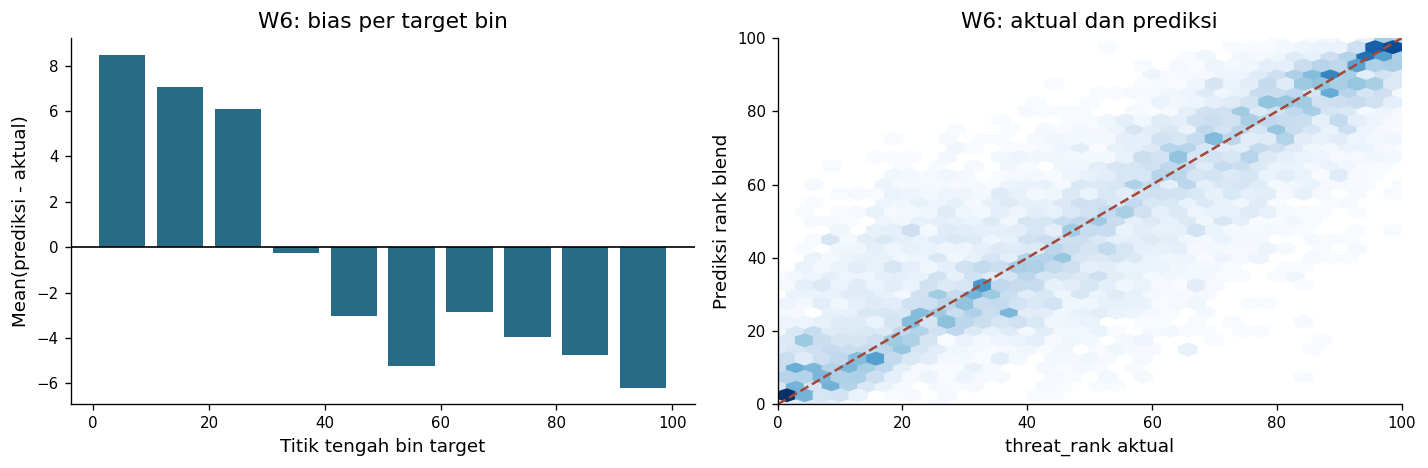

In [15]:
masks = {
    "Semua": np.ones(len(outer_valid), dtype=bool),
    "EF0": outer_valid.entry_friction.eq(0).to_numpy(),
    "EF1": outer_valid.entry_friction.eq(1).to_numpy(),
    "Target <=5": y_outer <= 5,
    "Target >=95": y_outer >= 95,
    "Stream missing": stream_missing_mask(outer_valid),
    "Stream present": ~stream_missing_mask(outer_valid),
}
fresh_subgroups = pd.DataFrame(
    [
        {
            "kelompok": name,
            "n": int(mask.sum()),
            "MAE W6": float(np.abs(error[mask]).mean()) if mask.any() else np.nan,
            "bias W6": float(error[mask].mean()) if mask.any() else np.nan,
        }
        for name, mask in masks.items()
    ]
)
display(fresh_subgroups.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_bins = pd.cut(y_outer, np.arange(0, 101, 10), include_lowest=True)
mean_bias = pd.DataFrame({"target bin": target_bins, "error": error})
mean_bias = mean_bias.groupby("target bin", observed=True)["error"].mean()
axes[0].bar(
    np.arange(len(mean_bias)) * 10 + 5,
    mean_bias,
    width=8,
    color="#276b86",
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(
    title="W6: bias per target bin",
    xlabel="Titik tengah bin target",
    ylabel="Mean(prediksi - aktual)",
)
axes[1].hexbin(y_outer, outer_prediction, gridsize=35, mincnt=1, cmap="Blues")
axes[1].plot([0, 100], [0, 100], "--", color="#a34837")
axes[1].set(
    title="W6: aktual dan prediksi",
    xlabel="threat_rank aktual",
    ylabel="Prediksi rank blend",
    xlim=(0, 100),
    ylim=(0, 100),
)
fig.tight_layout()
plt.show()


Pada grafik bias, target rendah cenderung diprediksi terlalu tinggi dan target tinggi terlalu rendah. Prediksi mendekati nilai tengah dapat memberi MAE yang baik secara keseluruhan, tetapi masih kurang tepat pada target ekstrem.

Sebagian Test memiliki nilai count nol tanpa analog Train; maknanya belum diketahui. Tanpa label Test, risikonya belum dapat diukur. Banyaknya eksperimen juga membatasi kekuatan kesimpulan generalisasi.

## 7. Melatih model akhir dan membuat prediksi Test

Evaluasi sebelumnya memisahkan data masa lalu untuk melatih model dan cycle berikutnya untuk mengukur error. Setelah pendekatan dipilih, model dilatih ulang memakai **seluruh 50.608 baris Train**, agar prediksi official Test memanfaatkan semua label yang tersedia. Tahap inilah yang disebut **refit penuh**.

Sel di bawah menjalankannya jika `RUN_FULL_TRAIN = True`: seluruh preprocessing dipelajari ulang dari Train, kemudian model memprediksi Test dan menyimpan CSV lokal. Nilainya dibiarkan `False` saat demonstrasi agar tidak mengulang pembuatan file; **evaluasi temporal di bagian sebelumnya tetap dijalankan**.

Tahap ini tidak menghasilkan skor validasi baru karena label Test tidak tersedia. Angka public Kaggle yang ditampilkan berasal dari submission historis, bukan dihitung oleh sel ini.

In [16]:
RUN_FULL_TRAIN = False
if RUN_FULL_TRAIN:
    if REGRESSION_FILES["test"] is None or REGRESSION_FILES["sample"] is None:
        raise FileNotFoundError("Official Regression Test dan SampleSubmission diperlukan.")
    assert sha256_file(REGRESSION_FILES["test"]) == (
        "4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c"
    )
    assert sha256_file(REGRESSION_FILES["sample"]) == (
        "63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533cd39dc854ffc190a32"
    )
    test = pd.read_csv(REGRESSION_FILES["test"])
    sample = pd.read_csv(REGRESSION_FILES["sample"])
    assert test.shape == (29421, 18)
    assert "threat_rank" not in test
    assert set(test.columns) == set(train.columns) - {"threat_rank"}
    assert test.record_id.is_unique
    assert not set(train.record_id) & set(test.record_id)
    assert test.cycle_code.between(80, 91).all()
    assert sample.columns.tolist() == ["record_id", "threat_rank"]
    assert sample.record_id.tolist() == test.record_id.tolist()

    deployment_choices = []
    for params_id in ("base", "regularized"):
        if params_id == chosen.param:
            raw = outer_raw
        else:
            _, raw = fit_predict(params_id, outer_train, outer_valid)
        for alpha in (0.0, 0.25, 0.50, 0.75, 1.0):
            mapped = rank_blend(raw, outer_valid.cycle_code, alpha)
            deployment_choices.append(
                {
                    "param": params_id,
                    "alpha": alpha,
                    "mae": mean_absolute_error(y_outer, mapped),
                }
            )
    deployment = sorted(
        deployment_choices,
        key=lambda row: (row["mae"], row["param"], row["alpha"]),
    )[0]
    assert deployment["param"] == "base"
    assert deployment["alpha"] == 0.50

    final_model, test_raw = fit_predict(deployment["param"], train, test)
    test_prediction = rank_blend(test_raw, test.cycle_code, deployment["alpha"])
    assert test_prediction.shape == (29421,)
    assert np.isfinite(test_prediction).all()
    assert np.all((test_prediction >= 0) & (test_prediction <= 100))
    output = sample.copy()
    output["threat_rank"] = test_prediction
    assert len(output) == 29421 and output.record_id.is_unique
    assert output.record_id.tolist() == test.record_id.tolist()
    assert output.threat_rank.notna().all()
    assert np.isfinite(output.threat_rank.to_numpy()).all()
    assert output.threat_rank.between(0, 100).all()

    destination = Path(
        os.environ.get(
            "SAMUEL_REGRESSION_PREDICTION_PATH",
            Path.cwd() / "regression_reproduced.csv",
        )
    ).expanduser()
    if not destination.is_absolute():
        destination = Path.cwd() / destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes = output.to_csv(index=False, float_format="%.17g").encode("utf-8")
    if destination.exists() and destination.read_bytes() != csv_bytes:
        raise FileExistsError("Output sebelumnya berbeda; periksa sebelum mengganti file.")
    destination.write_bytes(csv_bytes)
    print("Deployment:", deployment)
    print("Full Train fit rows:", len(train))
    print("CSV lokal siap diperiksa; tidak ada upload otomatis.")
    print("Prediction CSV SHA-256:", sha256_file(destination))
else:
    print("Flag False: refit penuh dan Test inference dilewati; CSV tidak dibuat.")


Flag False: refit penuh dan Test inference dilewati; CSV tidak dibuat.


## 8. Kesimpulan

EDA menunjukkan bahwa perbandingan proporsi artifact pada teks kosong dan terisi dipengaruhi waktu serta volume laporan. Gap awal **+3,66 pp** berubah menjadi sekitar **-2,2 sampai -2,3 pp** setelah penyesuaian. Analisis ini memakai target Classification; manfaat teks untuk prediksi `threat_rank` harus dinilai melalui eksperimen Regression tersendiri.

Dalam eksperimen Regression, fitur structured memperbaiki baseline median, kemudian tambahan teks kembali menurunkan MAE. LightGBM L1 dengan TF-IDF/SVD32 dan inner-selected rank blend dipilih karena mencapai **primary MAE 11,9316**. Rank blend menyesuaikan jarak prediksi dalam setiap cycle tanpa menggunakan label inference.

Pilihan tersebut memiliki trade-off. H12 LightGBM adalah **14,7040**, sedangkan hybrid Ridge lebih baik pada **13,9381**. Prediksi juga masih terlalu tinggi pada target rendah dan terlalu rendah pada target tinggi. Karena itu, rata-rata MAE yang baik belum berarti error sudah merata pada semua horizon dan kelompok target.

Public benchmark approach individual ini adalah **11,71363**, terpisah dari validasi internal. Seluruh window telah digunakan dalam development, dan label Test belum tersedia; hasil tidak menjamin private generalization. EDA dan evaluasi model bersama-sama membantu menjelaskan data, alasan pemilihan pendekatan, serta keterbatasan keputusan tersebut.